In [22]:
import pandas as pd

df = pd.read_csv("../data/raw/Clean_Dataset.csv")

In [23]:
df.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [24]:
df.airline.value_counts()

airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64

In [25]:
df.source_city.value_counts()

source_city
Delhi        61343
Mumbai       60896
Bangalore    52061
Kolkata      46347
Hyderabad    40806
Chennai      38700
Name: count, dtype: int64

In [26]:
df.destination_city.value_counts()

destination_city
Mumbai       59097
Delhi        57360
Bangalore    51068
Kolkata      49534
Hyderabad    42726
Chennai      40368
Name: count, dtype: int64

In [27]:
df.departure_time.value_counts()

departure_time
Morning          71146
Early_Morning    66790
Evening          65102
Night            48015
Afternoon        47794
Late_Night        1306
Name: count, dtype: int64

In [28]:
df.arrival_time.value_counts()

arrival_time
Night            91538
Evening          78323
Morning          62735
Afternoon        38139
Early_Morning    15417
Late_Night       14001
Name: count, dtype: int64

In [29]:
df.stops.value_counts()

stops
one            250863
zero            36004
two_or_more     13286
Name: count, dtype: int64

In [30]:
df["class"].value_counts()

class
Economy     206666
Business     93487
Name: count, dtype: int64

In [31]:
float(df["duration"].max())

49.83

In [32]:
float(df["duration"].min())

0.83

In [33]:
float(df["duration"].median())

11.25

## Preprocesing

In [34]:
df = df.drop("Unnamed: 0", axis=1)
df = df.drop("flight", axis=1)

df["class"] = df["class"].apply(lambda x: 1 if x == "Business" else 0)

In [35]:
df["stops"] = pd.factorize(df["stops"])[0]

In [36]:
df["stops"]

0         0
1         0
2         0
3         0
4         0
         ..
300148    1
300149    1
300150    1
300151    1
300152    1
Name: stops, Length: 300153, dtype: int64

In [37]:
float(df.duplicated().sum())

2213.0

In [38]:
df[df.duplicated(keep=False)]

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
9,GO_FIRST,Delhi,Afternoon,0,Evening,Mumbai,0,2.25,1,5954
10,GO_FIRST,Delhi,Afternoon,0,Evening,Mumbai,0,2.25,1,5954
154,Vistara,Delhi,Afternoon,0,Evening,Mumbai,0,2.17,2,7530
155,Vistara,Delhi,Afternoon,0,Evening,Mumbai,0,2.17,2,7530
400,SpiceJet,Delhi,Early_Morning,0,Morning,Mumbai,0,2.33,4,5953
...,...,...,...,...,...,...,...,...,...,...
255218,Vistara,Bangalore,Evening,1,Morning,Kolkata,1,14.75,38,60508
255290,Vistara,Bangalore,Evening,1,Morning,Kolkata,1,14.75,39,60508
255291,Vistara,Bangalore,Evening,1,Morning,Kolkata,1,14.75,39,60508
255353,Vistara,Bangalore,Evening,1,Morning,Kolkata,1,14.75,40,60508


In [39]:
df = df.drop_duplicates().reset_index(drop=True)


In [40]:
df

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,Delhi,Evening,0,Night,Mumbai,0,2.17,1,5953
1,SpiceJet,Delhi,Early_Morning,0,Morning,Mumbai,0,2.33,1,5953
2,AirAsia,Delhi,Early_Morning,0,Early_Morning,Mumbai,0,2.17,1,5956
3,Vistara,Delhi,Morning,0,Afternoon,Mumbai,0,2.25,1,5955
4,Vistara,Delhi,Morning,0,Morning,Mumbai,0,2.33,1,5955
...,...,...,...,...,...,...,...,...,...,...
297935,Vistara,Chennai,Morning,1,Evening,Hyderabad,1,10.08,49,69265
297936,Vistara,Chennai,Afternoon,1,Night,Hyderabad,1,10.42,49,77105
297937,Vistara,Chennai,Early_Morning,1,Night,Hyderabad,1,13.83,49,79099
297938,Vistara,Chennai,Early_Morning,1,Evening,Hyderabad,1,10.00,49,81585


In [41]:
df = df.join(pd.get_dummies(df.airline, dtype=int, prefix="airline")).drop(
    "airline", axis=1
)
df = df.join(pd.get_dummies(df.source_city, dtype=int, prefix="source")).drop(
    "source_city", axis=1
)
df = df.join(pd.get_dummies(df.destination_city, dtype=int, prefix="destination")).drop(
    "destination_city", axis=1
)
df = df.join(pd.get_dummies(df.arrival_time, dtype=int, prefix="arrival")).drop(
    "arrival_time", axis=1
)
df = df.join(pd.get_dummies(df.departure_time, dtype=int, prefix="departure")).drop(
    "departure_time", axis=1
)

In [42]:
df

,stops,class,duration,days_left,price,airline_AirAsia,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,...,arrival_Evening,arrival_Late_Night,arrival_Morning,arrival_Night,departure_Afternoon,departure_Early_Morning,departure_Evening,departure_Late_Night,departure_Morning,departure_Night
0,0,0,2.17,1,5953,0,0,0,0,1,...,0,0,0,1,0,0,1,0,0,0
1,0,0,2.33,1,5953,0,0,0,0,1,...,0,0,1,0,0,1,0,0,0,0
2,0,0,2.17,1,5956,1,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,0,0,2.25,1,5955,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,0,0,2.33,1,5955,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297935,1,1,10.08,49,69265,0,0,0,0,0,...,1,0,0,0,0,0,0,0,1,0
297936,1,1,10.42,49,77105,0,0,0,0,0,...,0,0,0,1,1,0,0,0,0,0
297937,1,1,13.83,49,79099,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,0
297938,1,1,10.00,49,81585,0,0,0,0,0,...,1,0,0,0,0,1,0,0,0,0


## Training Regression Model

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor


x, y = df.drop("price", axis=1), df.price

In [44]:
x

,stops,class,duration,days_left,airline_AirAsia,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,...,arrival_Evening,arrival_Late_Night,arrival_Morning,arrival_Night,departure_Afternoon,departure_Early_Morning,departure_Evening,departure_Late_Night,departure_Morning,departure_Night
0,0,0,2.17,1,0,0,0,0,1,0,...,0,0,0,1,0,0,1,0,0,0
1,0,0,2.33,1,0,0,0,0,1,0,...,0,0,1,0,0,1,0,0,0,0
2,0,0,2.17,1,1,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,0,0,2.25,1,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
4,0,0,2.33,1,0,0,0,0,0,1,...,0,0,1,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297935,1,1,10.08,49,0,0,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
297936,1,1,10.42,49,0,0,0,0,0,1,...,0,0,0,1,1,0,0,0,0,0
297937,1,1,13.83,49,0,0,0,0,0,1,...,0,0,0,1,0,1,0,0,0,0
297938,1,1,10.00,49,0,0,0,0,0,1,...,1,0,0,0,0,1,0,0,0,0


In [45]:
y

0          5953
1          5953
2          5956
3          5955
4          5955
          ...  
297935    69265
297936    77105
297937    79099
297938    81585
297939    81585
Name: price, Length: 297940, dtype: int64

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [47]:
reg = RandomForestRegressor(n_jobs=-1, random_state=42)
reg.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [48]:
reg.score(X_test, y_test)

0.9854045172026796

In [49]:
import math

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [50]:
y_pred = reg.predict(X_test)

print("mae", mean_absolute_error(y_test, y_pred))
print("mse", mean_squared_error(y_test, y_pred))
print("rmse", math.sqrt(mean_squared_error(y_test, y_pred)))
print(f"R2 Score: {r2_score(y_test, y_pred)}")


mae 1070.3350140860762
mse 7496668.023716351
rmse 2738.0043870885875
R2 Score: 0.9854045172026796


Text(0.5, 1.0, 'Predicted and Actual Price')

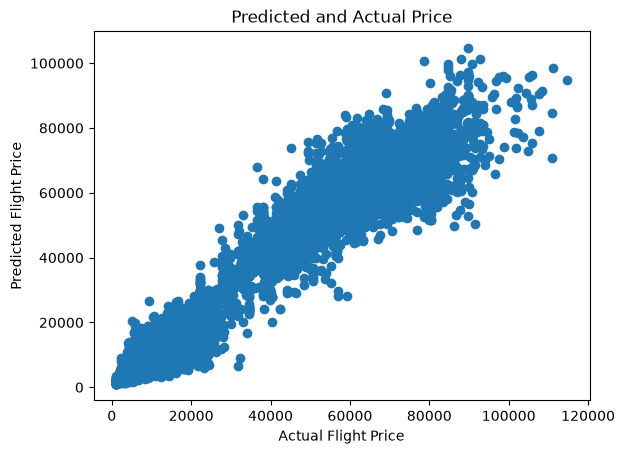

In [51]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Flight Price")
plt.ylabel("Predicted Flight Price")
plt.title("Predicted and Actual Price")

In [52]:
df.price.describe()

count    297940.000000
mean      20976.448604
std       22734.394635
min        1105.000000
25%        4792.000000
50%        7466.000000
75%       42521.000000
max      123071.000000
Name: price, dtype: float64

In [53]:
importances = {
    name: round(float(score), 4)
    for name, score in zip(reg.feature_names_in_, reg.feature_importances_)
}
sorted_importance = sorted(importances.items(), key=lambda x: x[1], reverse=True)

sorted_importance

[('class', 0.8806),
 ('duration', 0.0566),
 ('days_left', 0.0186),
 ('airline_Vistara', 0.0055),
 ('airline_Air_India', 0.0044),
 ('source_Delhi', 0.0039),
 ('destination_Delhi', 0.0033),
 ('source_Mumbai', 0.0022),
 ('destination_Mumbai', 0.0019),
 ('stops', 0.0018),
 ('destination_Kolkata', 0.0018),
 ('source_Kolkata', 0.0017),
 ('arrival_Evening', 0.0016),
 ('destination_Hyderabad', 0.0015),
 ('destination_Bangalore', 0.0013),
 ('source_Bangalore', 0.0012),
 ('source_Hyderabad', 0.0012),
 ('arrival_Night', 0.0012),
 ('departure_Evening', 0.0011),
 ('arrival_Afternoon', 0.001),
 ('source_Chennai', 0.0009),
 ('destination_Chennai', 0.0009),
 ('departure_Morning', 0.0009),
 ('departure_Afternoon', 0.0008),
 ('departure_Early_Morning', 0.0008),
 ('departure_Night', 0.0008),
 ('arrival_Early_Morning', 0.0007),
 ('arrival_Morning', 0.0007),
 ('airline_AirAsia', 0.0005),
 ('airline_Indigo', 0.0003),
 ('airline_GO_FIRST', 0.0001),
 ('arrival_Late_Night', 0.0001),
 ('departure_Late_Night', 0

<BarContainer object of 5 artists>

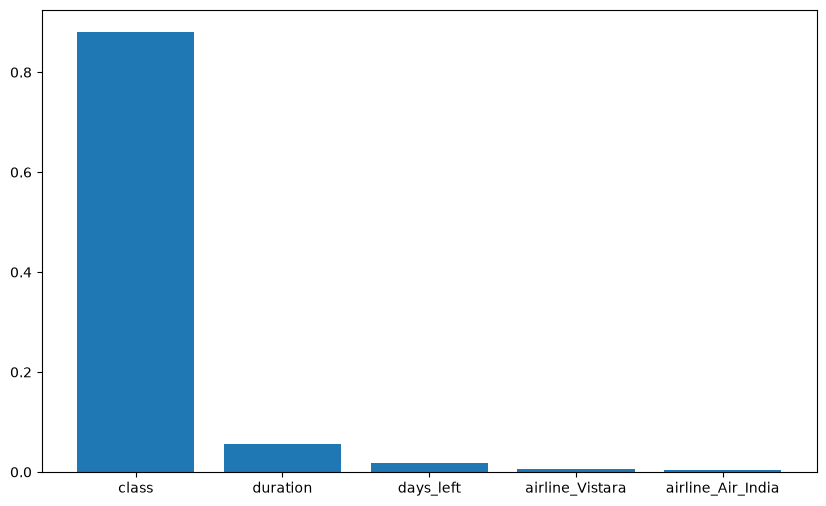

In [54]:
plt.figure(figsize=(10, 6))
plt.bar([x[0] for x in sorted_importance[:5]], [x[1] for x in sorted_importance[:5]])

In [55]:
import pandas as pd

# Create a blank row matching X_train's columns, filled with 0s
sample_flight = pd.DataFrame(0, index=[0], columns=X_train.columns)

# Fill in the details for your flight
sample_flight["class"] = 1  # e.g., 1 = Business, 0 = Economy (match your encoding)
sample_flight["duration"] = 2.5  # 2.5 hours
sample_flight["days_left"] = 10  # Booking 10 days ahead
sample_flight["stops"] = 0  # Non-stop
sample_flight["airline_Vistara"] = 1
sample_flight["source_Delhi"] = 1
sample_flight["destination_Mumbai"] = 1

predicted_price = reg.predict(sample_flight)[0]
print(f"Predicted Flight Price: {predicted_price:.2f}")


Predicted Flight Price: 37536.75
